# Efecto de capacitación sobre ingresos: incertidumbre y conclusiones

Consulta la [metodología](../docs/metodologia.md) y ejecuta las etapas en orden. Los comentarios se calculan con los resultados guardados.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("training_program_impact")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre este notebook desde su proyecto independiente.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from training_program_impact.alerts import configurar_notebook, mostrar_alertas
from IPython.display import display, Markdown, Image
configurar_notebook()


# Efecto de capacitación sobre ingresos: evaluacion

El IC ajustado HC3 **excluye cero por el lado positivo**. Se contrastan ambas estimaciones con **1000 réplicas bootstrap**, muestreando participantes dentro de cada brazo y recalculando el centrado. Diferencias entre métodos reflejan ajuste y aproximaciones de incertidumbre; no se comparan mediante accuracy ni se conoce un efecto verdadero con el que medir error. Interpretación causal condicionada a la asignación experimental, consistencia, ausencia de interferencia y selección de la submuestra. No se generaliza a todos los trabajadores, programas actuales ni efectos por cumplimiento.


,Indicador,Valor
0,bootstrap_replicas_validas,1000
1,bootstrap_replicas_solicitadas,1000
2,estimando,Efecto de asignación al programa en la muestra...


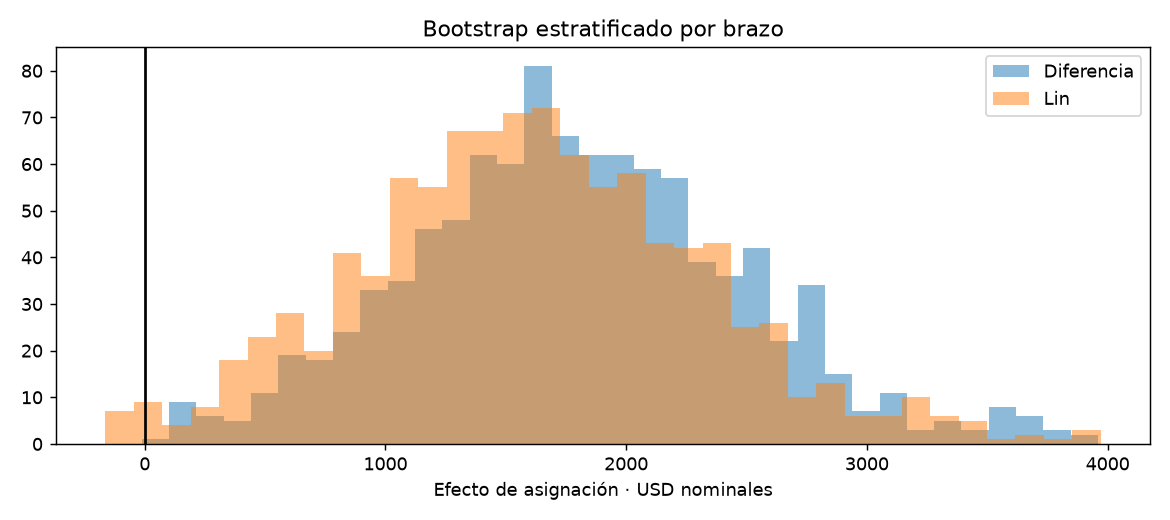

,estimador,efecto_usd,error_estandar,ci_inferior,ci_superior,confidence_level,bootstrap_inferior,bootstrap_superior,error_estandar_hc3,parametros
0,Diferencia experimental,1794.342404,670.996546,474.010470,3114.674339,0.95,468.027058,3286.222295,NaN,NaN
1,Ajuste Lin · HC3,1621.583101,NaN,212.544498,3030.621704,0.95,247.885579,3176.449679,716.872751,18.0


In [2]:
from training_program_impact.analysis import run_stage
import pandas as pd
metrics,comment=run_stage(PROJECT_ROOT,"evaluacion")
display(Markdown(comment))
scalars={k:v for k,v in metrics.items() if not isinstance(v,(dict,list))}
if scalars:display(pd.DataFrame(list(scalars.items()),columns=["Indicador","Valor"]))
if "candidatos" in metrics:display(pd.DataFrame(metrics["candidatos"]))
for filename in ["eda.png","evaluacion.png"]:
    path=PROJECT_ROOT/"reports/evaluacion"/filename
    if path.exists():display(Image(filename=str(path)))
for filename in ["estimaciones.csv","metricas_test.csv","horas_por_empleado.csv"]:
    path=PROJECT_ROOT/"reports/evaluacion"/filename
    if path.exists():display(pd.read_csv(path).head(20))

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from training_program_impact.informe import generar_informe
generar_informe(PROJECT_ROOT)
display(Markdown("[Abrir informe integral](../reports/informe_final/informe_final.md)"))

[Abrir informe integral](../reports/informe_final/informe_final.md)